# Simple pipeline example of ML using Perceptron
## Perceptron is the building block of many ML NN algorithms

In [1]:
import platform as pt
import sys
import os
import numpy as np
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
# import tensorflow as tf

I have Python 3.14 installed so tensorflow isnt working, so I commented it out

# Perceptron imports and Decisoin Plotting
# install the followingfor the Plotting of the results
conda install -c conda-forge mlxtend

In [2]:
from sklearn.linear_model import Perceptron
from mlxtend.plotting import plot_decision_regions

# Print statements to check the system

In [3]:
%matplotlib 
%matplotlib notebook 
%matplotlib inline 

print(pt.python_version())
print(sys.version)
print(sys.version_info)
# print("TensorFlow version:", tf.__version__)
print(os.getcwd())

Using matplotlib backend: module://matplotlib_inline.backend_inline
3.14.7
3.14.7 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 10:12:46) [MSC v.1942 64 bit (AMD64)]
sys.version_info(major=3, minor=14, micro=7, releaselevel='final', serial=0)
C:\Users\19563\Project_02_Perceptron_Pipeline


I commented out the tensor flow print command because I'm using Python 3.14 so tf isn't available

## Reading our data file csv. This one is almost ready to be trained...

In [4]:
! type .\sms_spam_perceptron.csv

"type","sex","buy"
"ham","0","1"
"ham","0","1"
"ham","1","1"
"spam","1","0"
"ham","0","1"
"spam","1","0"
"ham","0","1"
"ham","0","1"
"spam","2","1"
"ham","0","1"
"ham","0","1"
"ham","0","1"
"ham","0","1"
"ham","0","1"
"spam","1","0"
"ham","0","1"
"ham","0","2"
"ham","0","1"
"spam","1","2"
"ham","0","1"
"spam","1","0"
"ham","0","1"
"spam","1","0"
"ham","0","1"
"spam","2","0"
"ham","0","1"
"spam","1","0"
"ham","0","2"
"spam","1","0"
"ham","0","2"
"ham","0","1"
"ham","0","1"
"ham","1","0"
"ham","0","1"
"spam","1","0"
"ham","0","1"
"ham","0","1"
"ham","0","1"
"spam","1","0"
"ham","0","1"
"ham","1","0"
"ham","0","1"
"ham","0","1"
"ham","0","1"
"spam","1","0"
"ham","0","1"
"ham","0","1"
"spam","1","0"
"spam","1","0"
"spam","1","0"
"ham","1","0"
"ham","0","2"
"ham","0","1"
"ham","0","1"
"ham","1","0"
"ham","0","1"
"ham","0","1"
"spam","1","0"
"ham","0","1"
"ham","0","1"
"ham","1","0"
"spam","2","0"
"ham","1","0"
"ham","1","0"
"ham","0","1"
"ham","0","1"
"ham","0","1"
"ham","1","0"
"spam","1",

In [5]:
# Reading as csv with a header
df = pd.read_csv('./sms_spam_perceptron.csv')

In [6]:
type(df)

pandas.DataFrame

In [7]:
df.describe()

,sex,buy
count,99.000000,99.000000
mean,0.414141,0.747475
std,0.571609,0.628302
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,1.000000
75%,1.000000,1.000000
max,2.000000,3.000000


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   type    99 non-null     str  
 1   sex     99 non-null     int64
 2   buy     99 non-null     int64
dtypes: int64(2), str(1)
memory usage: 2.4 KB


In [9]:
df.head()

,type,sex,buy
0,ham,0,1
1,ham,0,1
2,ham,1,1
3,spam,1,0
4,ham,0,1


In [10]:
df.tail()

,type,sex,buy
94,ham,0,1
95,ham,0,1
96,ham,0,1
97,spam,1,0
98,ham,0,1


In [11]:
# Extract the label
y = df.iloc[:, 0].values

In [12]:
y

<StringArray>
[ 'ham',  'ham',  'ham', 'spam',  'ham', 'spam',  'ham',  'ham', 'spam',
  'ham',  'ham',  'ham',  'ham',  'ham', 'spam',  'ham',  'ham',  'ham',
 'spam',  'ham', 'spam',  'ham', 'spam',  'ham', 'spam',  'ham', 'spam',
  'ham', 'spam',  'ham',  'ham',  'ham',  'ham',  'ham', 'spam',  'ham',
  'ham',  'ham', 'spam',  'ham',  'ham',  'ham',  'ham',  'ham', 'spam',
  'ham',  'ham', 'spam', 'spam', 'spam',  'ham',  'ham',  'ham',  'ham',
  'ham',  'ham',  'ham', 'spam',  'ham',  'ham',  'ham', 'spam',  'ham',
  'ham',  'ham',  'ham',  'ham',  'ham', 'spam',  'ham',  'ham',  'ham',
  'ham',  'ham',  'ham', 'spam',  'ham',  'ham',  'ham',  'ham',  'ham',
  'ham', 'spam',  'ham', 'spam',  'ham', 'spam',  'ham',  'ham',  'ham',
  'ham',  'ham',  'ham',  'ham',  'ham',  'ham',  'ham', 'spam',  'ham']
Length: 99, dtype: str

In [13]:
# convert the word spam to -1 and the word ham to +1
y = np.where(y == 'spam', -1, 1)

In [14]:
y

array([ 1,  1,  1, -1,  1, -1,  1,  1, -1,  1,  1,  1,  1,  1, -1,  1,  1,
        1, -1,  1, -1,  1, -1,  1, -1,  1, -1,  1, -1,  1,  1,  1,  1,  1,
       -1,  1,  1,  1, -1,  1,  1,  1,  1,  1, -1,  1,  1, -1, -1, -1,  1,
        1,  1,  1,  1,  1,  1, -1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,
       -1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1, -1,  1, -1,
        1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1])

In [15]:
#pick the data without the label as X
X = df.iloc[:, [1, 2]].values

In [16]:
type(X)

numpy.ndarray

In [56]:
#output the shapes of X and y and their corresponding datatypes
print('X:', X.shape, 'data type: ', X.dtype)
print('y: ', y.shape, 'data type: ', y.dtype)

X: (99, 2) data type:  int64
y:  (99,) data type:  int64


In [17]:
X

array([[0, 1],
       [0, 1],
       [1, 1],
       [1, 0],
       [0, 1],
       [1, 0],
       [0, 1],
       [0, 1],
       [2, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [1, 0],
       [0, 1],
       [0, 2],
       [0, 1],
       [1, 2],
       [0, 1],
       [1, 0],
       [0, 1],
       [1, 0],
       [0, 1],
       [2, 0],
       [0, 1],
       [1, 0],
       [0, 2],
       [1, 0],
       [0, 2],
       [0, 1],
       [0, 1],
       [1, 0],
       [0, 1],
       [1, 0],
       [0, 1],
       [0, 1],
       [0, 1],
       [1, 0],
       [0, 1],
       [1, 0],
       [0, 1],
       [0, 1],
       [0, 1],
       [1, 0],
       [0, 1],
       [0, 1],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [0, 2],
       [0, 1],
       [0, 1],
       [1, 0],
       [0, 1],
       [0, 1],
       [1, 0],
       [0, 1],
       [0, 1],
       [1, 0],
       [2, 0],
       [1, 0],
       [1, 0],
       [0, 1],
       [0, 1],
       [0,

In [18]:
print(type(X))
print(X.dtype)

<class 'numpy.ndarray'>
int64


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   type    99 non-null     str  
 1   sex     99 non-null     int64
 2   buy     99 non-null     int64
dtypes: int64(2), str(1)
memory usage: 2.4 KB


In [20]:
df.describe()

,sex,buy
count,99.000000,99.000000
mean,0.414141,0.747475
std,0.571609,0.628302
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,1.000000
75%,1.000000,1.000000
max,2.000000,3.000000


In [21]:
y

array([ 1,  1,  1, -1,  1, -1,  1,  1, -1,  1,  1,  1,  1,  1, -1,  1,  1,
        1, -1,  1, -1,  1, -1,  1, -1,  1, -1,  1, -1,  1,  1,  1,  1,  1,
       -1,  1,  1,  1, -1,  1,  1,  1,  1,  1, -1,  1,  1, -1, -1, -1,  1,
        1,  1,  1,  1,  1,  1, -1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,
       -1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1, -1,  1, -1,
        1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1])

In [22]:
df

,type,sex,buy
0,ham,0,1
1,ham,0,1
2,ham,1,1
3,spam,1,0
4,ham,0,1
...,...,...,...
94,ham,0,1
95,ham,0,1
96,ham,0,1
97,spam,1,0


In [23]:
y = df.iloc[:, 0].values

In [24]:
y

<StringArray>
[ 'ham',  'ham',  'ham', 'spam',  'ham', 'spam',  'ham',  'ham', 'spam',
  'ham',  'ham',  'ham',  'ham',  'ham', 'spam',  'ham',  'ham',  'ham',
 'spam',  'ham', 'spam',  'ham', 'spam',  'ham', 'spam',  'ham', 'spam',
  'ham', 'spam',  'ham',  'ham',  'ham',  'ham',  'ham', 'spam',  'ham',
  'ham',  'ham', 'spam',  'ham',  'ham',  'ham',  'ham',  'ham', 'spam',
  'ham',  'ham', 'spam', 'spam', 'spam',  'ham',  'ham',  'ham',  'ham',
  'ham',  'ham',  'ham', 'spam',  'ham',  'ham',  'ham', 'spam',  'ham',
  'ham',  'ham',  'ham',  'ham',  'ham', 'spam',  'ham',  'ham',  'ham',
  'ham',  'ham',  'ham', 'spam',  'ham',  'ham',  'ham',  'ham',  'ham',
  'ham', 'spam',  'ham', 'spam',  'ham', 'spam',  'ham',  'ham',  'ham',
  'ham',  'ham',  'ham',  'ham',  'ham',  'ham',  'ham', 'spam',  'ham']
Length: 99, dtype: str

In [25]:
type(y)

pandas.arrays.StringArray

In [26]:
y = np.where(y == 'spam', -1, 1)

In [27]:
y


array([ 1,  1,  1, -1,  1, -1,  1,  1, -1,  1,  1,  1,  1,  1, -1,  1,  1,
        1, -1,  1, -1,  1, -1,  1, -1,  1, -1,  1, -1,  1,  1,  1,  1,  1,
       -1,  1,  1,  1, -1,  1,  1,  1,  1,  1, -1,  1,  1, -1, -1, -1,  1,
        1,  1,  1,  1,  1,  1, -1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,
       -1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1, -1,  1, -1,
        1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1])

In [28]:
X = df.iloc[:, [1, 2]].values

In [29]:
X

array([[0, 1],
       [0, 1],
       [1, 1],
       [1, 0],
       [0, 1],
       [1, 0],
       [0, 1],
       [0, 1],
       [2, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [1, 0],
       [0, 1],
       [0, 2],
       [0, 1],
       [1, 2],
       [0, 1],
       [1, 0],
       [0, 1],
       [1, 0],
       [0, 1],
       [2, 0],
       [0, 1],
       [1, 0],
       [0, 2],
       [1, 0],
       [0, 2],
       [0, 1],
       [0, 1],
       [1, 0],
       [0, 1],
       [1, 0],
       [0, 1],
       [0, 1],
       [0, 1],
       [1, 0],
       [0, 1],
       [1, 0],
       [0, 1],
       [0, 1],
       [0, 1],
       [1, 0],
       [0, 1],
       [0, 1],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [0, 2],
       [0, 1],
       [0, 1],
       [1, 0],
       [0, 1],
       [0, 1],
       [1, 0],
       [0, 1],
       [0, 1],
       [1, 0],
       [2, 0],
       [1, 0],
       [1, 0],
       [0, 1],
       [0, 1],
       [0,

In [30]:
type(X)

numpy.ndarray

# Splitting the data into Training and Testing

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=0)

In [32]:
print(len(X_train))
print(len(X_test))
print(len(y_train))
print(len(y_test))

79
20
79
20


In [33]:
print(X_train.shape)
print(y_train.shape)

(79, 2)
(79,)


In [34]:
print(type(X_train))
print(type(y_train))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [35]:
X_train.dtype

dtype('int64')

In [36]:
y_train

array([ 1,  1, -1,  1,  1, -1,  1,  1, -1,  1,  1,  1,  1, -1,  1,  1, -1,
        1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1, -1, -1,  1,  1,  1, -1,
       -1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1, -1, -1,  1,  1,
        1, -1,  1, -1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1, -1, -1])

In [37]:
y_train.shape

(79,)

In [38]:
y_train.dtype

dtype('int64')

In [39]:
#clf = Perceptron(max_iter=40, eta0=0.1, random_state=0)
clf =Perceptron(alpha=0.0001, class_weight=None, early_stopping=False, eta0=0.1,
      fit_intercept=True, max_iter=40, n_iter_no_change=5,
      n_jobs=None, penalty=None, random_state=0, shuffle=True, tol=None,
      validation_fraction=0.1, verbose=0, warm_start=False)

In [40]:
clf

,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",40
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",None
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",0.1
,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",0


In [41]:
clf.fit(X_train, y_train)

,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",40
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",None
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",0.1
,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",0


In [42]:
score  = clf.score(X, y)
print(score)

0.8080808080808081


In [43]:
y_pred = clf.predict(X_test)

In [44]:
print(y_pred)

[ 1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1 -1]


In [45]:
score

0.8080808080808081

In [46]:
y_pred

array([ 1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
       -1,  1, -1])

In [47]:
y_test

array([-1, -1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,
       -1,  1, -1])

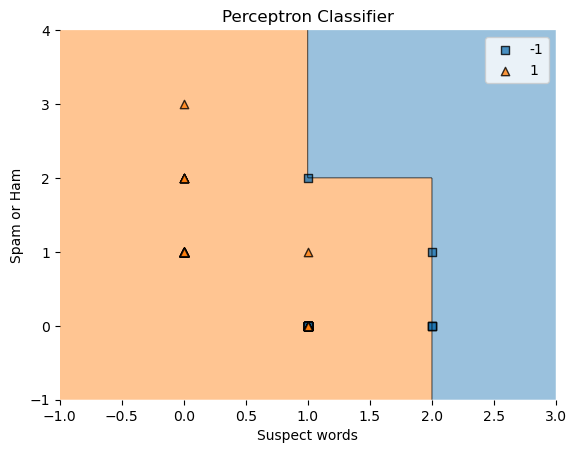

In [48]:
X_combined = np.vstack((X_train, X_test))
y_combined = np.hstack((y_train, y_test))

plot_decision_regions(X=X_combined, y=y_combined,clf=clf,legend=2)
# Adding axes annotations
plt.title('Perceptron Classifier')
plt.xlabel('Suspect words')
plt.ylabel('Spam or Ham')
plt.legend(loc='upper right')

#plt.tight_layout()
plt.show()

In [49]:
from sklearn.metrics import accuracy_score

print('Misclassified samples: %d' % (y_test != y_pred).sum())
print('Accuracy: %.2f' % accuracy_score(y_test, y_pred))

Misclassified samples: 4
Accuracy: 0.80


In [50]:
# Import metrics from the sklearn module
from sklearn.metrics import confusion_matrix

In [51]:
#Run the confusion matrix function on actual and predicted values
cm=confusion_matrix(y_test, y_pred,labels=clf.classes_)

In [52]:
cm

array([[ 2,  4],
       [ 0, 14]])

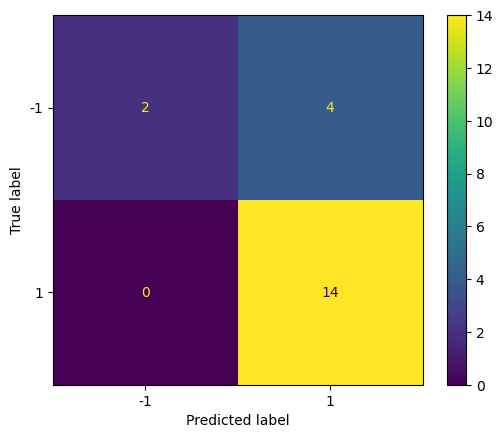

In [53]:
# Plot the confusion matrix
import matplotlib.pyplot as plt
# from sklearn.metrics import plot_confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
disp= ConfusionMatrixDisplay(cm, display_labels=clf.classes_)
disp.plot()

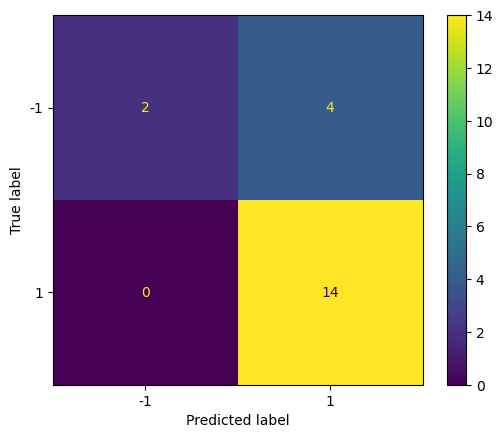

In [54]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Initialize the display with the confusion matrix and labels
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)

# Generate the plot
disp.plot()

# CRITICAL: This line forces the graph to display on your screen
plt.show()
